# Capítulo 6 — Quantização de LLMs: benchmark comparativo

Fonte: *Domain-Specific Small Language Models* (G. Iozzia, Cap. 6).

**Pergunta da apresentação:** dado um orçamento de memória e um hardware, qual técnica de redução de precisão usar, e quanto de qualidade se perde com ela?

Para responder, **todas as técnicas são aplicadas ao mesmo modelo e medidas com o mesmo código**:

- **Modelo:** `Qwen/Qwen2.5-1.5B-Instruct` (≈ 1,54 bilhão de parâmetros). A Qwen publica versões oficiais em **GPTQ** e **GGUF** desse mesmo modelo, então todas as variantes partem dos mesmos pesos.
- **Qualidade**, em três medidas complementares:
  - perplexidade no WikiText-2 (teste), em 32 janelas fixas de 512 tokens;
  - concordância do token mais provável (top-1) com o FP32;
  - acurácia no **HellaSwag** (500 questões de múltipla escolha), que mostra se a perda de perplexidade vira erro numa tarefa.
- **Custo:** tamanho dos pesos, pico de VRAM, tokens/s no *forward* (processamento do prompt, em lote) e tokens/s na geração, com lote 1 e numa varredura de lotes 1, 8 e 32.
- **Incerteza:** as diferenças de qualidade vêm com intervalo de confiança de 95% (bootstrap pareado), e as de velocidade com o mínimo e o máximo de 3 repetições.

Cada parte segue o mesmo roteiro: uma **hipótese** antes de medir e o **resultado** depois, dizendo se ela foi confirmada ou refutada. A Parte 5 reúne tudo numa tabela única, num gráfico de custo × qualidade e numa análise do tamanho de lote.

> **Execução:** *Ambiente de execução → Alterar tipo → GPU T4*. Rode o notebook inteiro **antes** da apresentação (≈ 1 hora no total, a maior parte nas Partes 1 a 3). Cada resultado é gravado em `resultados/`, então dá para rodar as partes separadamente ou retomar depois de uma reinicialização do ambiente.
>
> **Execução registrada aqui:** Colab com GPU T4 e PyTorch 2.15.0+cu132. Os números de velocidade dependem da versão das bibliotecas (ver Parte 5).

---
# Parte 0 — Configuração e protocolo de medição

In [ ]:
# Instalação das dependências (alguns minutos na primeira execução; o gptqmodel pode compilar kernels).
# Se o Colab pedir para reiniciar a sessão ao final, reinicie e siga a partir da próxima célula.
!pip install -q transformers accelerate bitsandbytes datasets pandas matplotlib
!pip install -q gptqmodel optimum
# Roda do llama.cpp já compilada para CPU (evita compilar do zero).
!pip install -q llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu
# Pacotes pré-instalados no Colab que o notebook não usa e que quebram quando o pip atualiza o PyTorch
# (o transformers tenta importá-los e eles exigem a mesma versão de CUDA do PyTorch).
!pip uninstall -y -q diffusers torchaudio torchvision

In [ ]:
import gc, os, re, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Dispositivo:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (as partes 1 a 3 exigem GPU)")

# ---------------- Configuração do benchmark ----------------
MODEL_ID   = "Qwen/Qwen2.5-1.5B-Instruct"            # pesos originais (BF16 no Hub)
GPTQ_ID    = "Qwen/Qwen2.5-1.5B-Instruct-GPTQ-Int4"  # mesmo modelo, já quantizado com GPTQ
GGUF_REPO  = "Qwen/Qwen2.5-1.5B-Instruct-GGUF"       # mesmo modelo, em GGUF (llama.cpp)

SEQ_LEN    = 512   # tokens por janela de avaliação
N_WINDOWS  = 32    # janelas na GPU (32 x 512 = 16.384 tokens)
BS         = 4     # janelas por lote no forward
GEN_TOKENS = 128   # tokens gerados para medir a velocidade de geração
N_WIN_GGUF = 4     # janelas na CPU (as primeiras 4 do mesmo conjunto; a CPU é bem mais lenta)
PROMPT     = "The history of artificial intelligence began"

OUT_DIR = "resultados"
os.makedirs(OUT_DIR, exist_ok=True)
CSV_GPU  = os.path.join(OUT_DIR, "benchmark_gpu.csv")
CSV_GGUF = os.path.join(OUT_DIR, "benchmark_gguf.csv")

# ---------------- Medições adicionais (feitas dentro de rodar(), com o modelo já carregado) ----------------
MEDIR_TAREFA = True        # acurácia no HellaSwag: escolher a continuação certa entre 4
N_TAREFA     = 500         # exemplos sorteados (com SEED) do conjunto de validação
MEDIR_LOTES  = True        # velocidade de geração com vários prompts em paralelo
LOTES        = (1, 8, 32)  # tamanhos de lote da varredura
N_REP_LOTES  = 3           # repetições por lote (guarda todas; a síntese usa mediana, mín. e máx.)
CSV_TAREFA = os.path.join(OUT_DIR, "benchmark_tarefa.csv")
CSV_LOTES  = os.path.join(OUT_DIR, "benchmark_lotes.csv")

PyTorch: 2.15.0+cu132
Dispositivo: Tesla T4


### Protocolo de medição

A mesma função `rodar()` é usada para todas as técnicas em GPU. Ela recebe apenas uma função que **carrega** o modelo; todo o resto é idêntico:

1. Zera o pico de memória da GPU e carrega o modelo.
2. **Forward:** passa as 32 janelas fixas do WikiText-2 em lotes de 4 e mede tokens/s e perplexidade. A perda de cada janela é gravada em `nll_*.npy`, para o cálculo dos intervalos de confiança.
3. **Geração:** gera 128 tokens de forma gulosa (*greedy*) a partir do mesmo prompt, 3 vezes, e reporta a **mediana** de tokens/s, com o mínimo e o máximo.
4. Compara as previsões top-1 com as do FP32 (concordância) e grava tudo em CSV.
5. **HellaSwag:** cada questão traz o início de uma cena e 4 continuações possíveis. O modelo pontua cada continuação pela soma dos log-probs dos seus tokens dividida pelo número de caracteres (`acc_norm`, o mesmo critério do `lm-eval-harness`) e acerta quando a maior pontuação é a da continuação correta. O acaso dá 25%.
6. **Varredura de lotes:** gera 128 tokens para 1, 8 e 32 cópias do prompt ao mesmo tempo e mede tokens/s agregados e pico de VRAM.

Os passos 5 e 6 vêm depois da leitura do pico de VRAM, para não alterá-lo.

$$\text{PPL} = \exp\!\left(-\frac{1}{N}\sum_{i=1}^{N}\log p(x_i \mid x_{<i})\right)$$

**Forward × geração.** O *forward* em lote mede o regime limitado por **cálculo**. A geração token a token, em teoria, é limitada pela **largura de banda de memória**: a cada token, todos os pesos são lidos da VRAM. Se isso valer, pesos menores geram mais rápido, e é aí que a quantização mais ajudaria. Num modelo pequeno como este, porém, cada token dispara centenas de kernels curtos, e o tempo pode ser dominado pelo *overhead* do framework e da CPU. A varredura de lotes da Parte 5 testa qual dos dois regimes vale aqui.

**Incerteza.** Perplexidade e HellaSwag são medidos numa amostra (32 janelas e 500 questões). Para saber se uma diferença entre técnicas é real, a Parte 5 usa **bootstrap pareado**: sorteia com reposição, 10 mil vezes, um novo conjunto de janelas (ou questões), **o mesmo para todas as técnicas**, e observa como a diferença varia. Como a dificuldade das janelas muda muito, mas afeta todas as técnicas da mesma forma, comparar na mesma amostra cancela essa variação. As janelas são trechos consecutivos do texto, não totalmente independentes, então os intervalos tendem a sair um pouco otimistas.

In [ ]:
def liberar_memoria():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

def sync():
    # Espera a GPU terminar antes de ler o cronômetro (as chamadas CUDA são assíncronas).
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def slug(nome):
    return re.sub(r"[^A-Za-z0-9]+", "_", nome).strip("_")

def salvar_linha(linhas, caminho):
    # Grava uma linha (dict) ou várias (lista de dicts). Substitui as linhas das mesmas técnicas,
    # se elas já tiverem sido medidas antes.
    linhas = [linhas] if isinstance(linhas, dict) else linhas
    df = pd.read_csv(caminho) if os.path.exists(caminho) else pd.DataFrame()
    if len(df):
        df = df[~df["técnica"].isin({l["técnica"] for l in linhas})]
    df = pd.concat([df, pd.DataFrame(linhas)], ignore_index=True)
    df.to_csv(caminho, index=False)

# ---------------- Dados fixos de avaliação ----------------
tok = AutoTokenizer.from_pretrained(MODEL_ID)
texto = "\n\n".join(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")["text"])
ids = tok(texto, return_tensors="pt").input_ids[0][: SEQ_LEN * N_WINDOWS].view(N_WINDOWS, SEQ_LEN)
print("Janelas de avaliação:", tuple(ids.shape))

# HellaSwag: dado o início de uma cena, escolher entre 4 continuações. Mesmo pré-processamento
# do lm-eval-harness, para os números serem comparáveis aos publicados.
def _limpar_hs(t):
    t = t.strip().replace(" [title]", ". ")
    t = re.sub(r"\[.*?\]", "", t)
    return t.replace("  ", " ")

tarefa = []
if MEDIR_TAREFA:
    _hs = load_dataset("Rowan/hellaswag", split="validation")
    _sel = np.sort(np.random.default_rng(SEED).choice(len(_hs), N_TAREFA, replace=False))
    for ex in _hs.select(_sel):
        ctx = _limpar_hs(ex["activity_label"] + ": " + ex["ctx_a"] + " " + ex["ctx_b"].capitalize())
        finais = [_limpar_hs(f) for f in ex["endings"]]
        tarefa.append({"ctx": tok(ctx).input_ids,
                       "conts": [tok(" " + f).input_ids for f in finais],
                       "n_chars": np.array([len(f) for f in finais]),
                       "label": int(ex["label"])})
    print("Exemplos do HellaSwag:", len(tarefa))

@torch.no_grad()
def eval_forward(model):
    # Retorna (tokens/s, perplexidade, NLL por janela, previsões top-1).
    dev = model.device
    model(ids[:BS].to(dev)); sync()                       # aquecimento
    nll_jan, preds, elapsed = [], [], 0.0
    for i in range(0, N_WINDOWS, BS):
        x = ids[i:i + BS].to(dev)
        sync(); t0 = time.perf_counter()
        logits = model(x).logits
        sync(); elapsed += time.perf_counter() - t0

        logits = logits[:, :-1].float()                   # a perda é sempre calculada em FP32
        tgt = x[:, 1:]
        nll = F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), reduction="none")
        nll_jan.append(nll.view(x.size(0), -1).sum(1).double().cpu())
        preds.append(logits.argmax(-1).cpu())
        del logits, nll
    nll_jan = torch.cat(nll_jan).numpy()
    ppl = float(np.exp(nll_jan.sum() / (N_WINDOWS * (SEQ_LEN - 1))))
    return ids.numel() / elapsed, ppl, nll_jan, torch.cat(preds)

N_REP_GEN = 3   # repetições da geração; reporta a mediana (e grava mínimo e máximo)
GEN_KW = dict(do_sample=False, temperature=None, top_p=None, top_k=None, pad_token_id=tok.eos_token_id)

@torch.no_grad()
def eval_generate(model, n_rep=N_REP_GEN):
    # Tokens/s na geração gulosa com lote 1 (mediana de n_rep execuções) e o texto gerado.
    inp = tok(PROMPT, return_tensors="pt").to(model.device)
    kw = GEN_KW
    model.generate(**inp, max_new_tokens=8, min_new_tokens=8, **kw)        # aquecimento
    tps = []
    for _ in range(n_rep):
        sync(); t0 = time.perf_counter()
        out = model.generate(**inp, max_new_tokens=GEN_TOKENS, min_new_tokens=GEN_TOKENS, **kw)
        sync(); tps.append(GEN_TOKENS / (time.perf_counter() - t0))
    eval_generate.medidas = tps                                             # guarda as medições individuais
    gerado = tok.decode(out[0, inp.input_ids.shape[1]:], skip_special_tokens=True)
    return float(np.median(tps)), gerado

@torch.no_grad()
def eval_tarefa(model):
    # Para cada exemplo do HellaSwag, soma o log-prob de cada continuação e escolhe a maior.
    # Retorna uma matriz (exemplos, 2) com acerto em `acc` (soma bruta) e em `acc_norm`
    # (soma dividida pelo número de caracteres, que não favorece continuações curtas).
    dev, acertos = model.device, []
    for ex in tarefa:
        n_ctx, conts = len(ex["ctx"]), ex["conts"]
        L = n_ctx + max(len(c) for c in conts)
        x = torch.full((len(conts), L), tok.pad_token_id)
        mask = torch.zeros_like(x)
        for j, c in enumerate(conts):                          # padding à direita
            x[j, :n_ctx + len(c)] = torch.tensor(ex["ctx"] + c)
            mask[j, :n_ctx + len(c)] = 1
        # O contexto é o mesmo nas 4 sequências, então só as posições a partir do fim dele precisam
        # de logits (economiza memória: o vocabulário tem ~152 mil tokens).
        k = L - n_ctx + 1
        try:
            logits = model(x.to(dev), attention_mask=mask.to(dev), logits_to_keep=k).logits
        except TypeError:                                      # versões antigas do transformers
            logits = model(x.to(dev), attention_mask=mask.to(dev)).logits
        logp = logits[:, -k:-1].float().log_softmax(-1)
        lp = logp.gather(-1, x[:, n_ctx:, None].to(dev)).squeeze(-1) * mask[:, n_ctx:].to(dev)
        soma = lp.sum(1).cpu().numpy()
        acertos.append((soma.argmax() == ex["label"], (soma / ex["n_chars"]).argmax() == ex["label"]))
        del logits, logp
    return np.array(acertos)

@torch.no_grad()
def eval_lotes(model, nome):
    # Tokens/s agregados (lote x tokens / tempo) gerando GEN_TOKENS para LOTES cópias do mesmo prompt.
    # Com lote 1, cada passo lê todos os pesos para produzir um único token; com lotes maiores,
    # a mesma leitura serve a vários tokens, e o gargalo migra da memória para o cálculo.
    linhas = []
    for b in LOTES:
        inp = tok([PROMPT] * b, return_tensors="pt").to(model.device)
        try:
            model.generate(**inp, max_new_tokens=8, min_new_tokens=8, **GEN_KW)   # aquecimento
            for r in range(N_REP_LOTES):
                if DEVICE == "cuda":
                    torch.cuda.reset_peak_memory_stats()
                sync(); t0 = time.perf_counter()
                model.generate(**inp, max_new_tokens=GEN_TOKENS, min_new_tokens=GEN_TOKENS, **GEN_KW)
                sync(); dt = time.perf_counter() - t0
                vram = torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else float("nan")
                linhas.append({"técnica": nome, "lote": b, "rep": r, "tok_s": b * GEN_TOKENS / dt,
                               "vram_pico_GB": vram, "erro": ""})
        except Exception as e:                    # ex.: falta de memória ou kernel sem suporte ao lote
            msg = f"{type(e).__name__}: {str(e).splitlines()[0][:120] if str(e) else ''}"
            print(f"Lote {b}: falhou ({msg})")
            linhas.append({"técnica": nome, "lote": b, "rep": 0, "tok_s": float("nan"),
                           "vram_pico_GB": float("nan"), "erro": msg})
            liberar_memoria()
    return linhas

def rodar(nome, carregar, bits):
    # Carrega o modelo com `carregar()`, mede tudo e grava uma linha em CSV_GPU.
    liberar_memoria()
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    res = carregar()
    model, obs = res if isinstance(res, tuple) else (res, "")
    model.eval()
    t_carga = time.perf_counter() - t0

    pesos_gb = model.get_memory_footprint() / 2**30
    fwd_tps, ppl, nll, preds = eval_forward(model)
    gen_tps, gerado = eval_generate(model)
    gen_min, gen_max = min(eval_generate.medidas), max(eval_generate.medidas)
    vram = torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else float("nan")

    ref = os.path.join(OUT_DIR, "preds_fp32.pt")
    if nome == "FP32":
        torch.save(preds, ref)
    concord = (preds == torch.load(ref)).float().mean().item() * 100 if os.path.exists(ref) else float("nan")
    np.save(os.path.join(OUT_DIR, f"nll_{slug(nome)}.npy"), nll)

    linha = {"técnica": nome, "bits": bits, "pesos_GB": pesos_gb, "vram_pico_GB": vram,
             "forward_tok_s": fwd_tps, "geração_tok_s": gen_tps,
             "geração_tok_s_min": gen_min, "geração_tok_s_max": gen_max, "perplexidade": ppl,
             "concordância_fp32_pct": concord, "carga_s": t_carga, "obs": obs, "texto_gerado": gerado}
    salvar_linha(linha, CSV_GPU)

    # As medições adicionais vêm depois da leitura do pico de VRAM, para não alterá-lo.
    extras = []
    if MEDIR_TAREFA and tarefa:
        t0 = time.perf_counter()
        acertos = eval_tarefa(model)
        np.save(os.path.join(OUT_DIR, f"hellaswag_{slug(nome)}.npy"), acertos)
        salvar_linha({"técnica": nome, "n_exemplos": len(acertos), "acc_pct": acertos[:, 0].mean() * 100,
                      "acc_norm_pct": acertos[:, 1].mean() * 100, "tempo_s": time.perf_counter() - t0},
                     CSV_TAREFA)
        extras.append(f"HellaSwag acc_norm: {acertos[:, 1].mean() * 100:.1f}% ({len(acertos)} exemplos)")
    if MEDIR_LOTES:
        lotes = pd.DataFrame(eval_lotes(model, nome))
        salvar_linha(lotes.to_dict("records"), CSV_LOTES)
        med = lotes.groupby("lote")["tok_s"].median()
        extras.append("Geração por lote (tok/s): " + ", ".join(f"{b}: {v:.1f}" for b, v in med.items()))
    del model
    liberar_memoria()

    if not np.isfinite(ppl):
        print("ATENÇÃO: perplexidade não finita (overflow numérico).")
    resumo = {k: (round(v, 3) if isinstance(v, float) else v) for k, v in linha.items() if k != "texto_gerado"}
    display(pd.Series(resumo, name=nome).to_frame())
    for e in extras:
        print(e)
    print("Texto gerado:", gerado[:200].replace("\n", " "), "...")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

... (18 outputs left out)

Generating train split:   0%|          | 0/39905 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10042 [00:00<?, ? examples/s]

Exemplos do HellaSwag: 500


---
# Parte 1 — Ponto flutuante: FP32, FP16 e BF16

Cada número tem **sinal**, **expoente** (faixa de valores) e **mantissa** (precisão):

| Formato | Sinal | Expoente | Mantissa | Característica |
|---|---|---|---|---|
| FP32 | 1 | 8 | 23 | Padrão em *deep learning* |
| FP16 | 1 | 5 | 10 | Mais precisão que o BF16, faixa muito menor |
| BF16 | 1 | 8 | 7 | Mesma faixa do FP32, menos precisão |

Reduzir para 16 bits é só informar `dtype` no carregamento: os valores são **arredondados** para o formato mais próximo, sem calibração, escala ou zero-point. É a redução mais simples, e também a que menos economiza (2×).

**Quando usar:** sempre que o modelo couber em 16 bits. **BF16** se a GPU suportar nativamente (Ampere ou mais recente, como A100, L4, RTX 30xx/40xx), porque não estoura; **FP16** em GPUs mais antigas, como a T4.

> **Hipótese.** Com 10 bits de mantissa, o FP16 deve ter perplexidade e acurácia praticamente idênticas às do FP32, com metade da memória. O *forward* deve ficar bem mais rápido, porque a T4 tem *tensor cores* para FP16 e não para FP32. Na geração, o ganho depende de ela ser limitada pela leitura da memória.

In [ ]:
# Propriedades de cada formato.
formatos = {"FP32": torch.float32, "FP16": torch.float16, "BF16": torch.bfloat16}
display(pd.DataFrame([{"formato": n, "bits": torch.finfo(d).bits, "maior valor": torch.finfo(d).max,
                       "menor normal": torch.finfo(d).tiny, "epsilon": torch.finfo(d).eps}
                      for n, d in formatos.items()]).set_index("formato"))

# Faixa (expoente) versus precisão (mantissa).
x = torch.tensor([70000.0, 1.001, 1e-8])
display(pd.DataFrame({n: x.to(d).float().tolist() for n, d in formatos.items()},
                     index=["70000", "1.001", "1e-8"]))
# FP16: 70000 vira inf (estouro) e 1e-8 vira 0 (underflow), mas 1.001 é representado.
# BF16: representa 70000 e 1e-8 de forma aproximada, mas arredonda 1.001 para 1.0.

,bits,maior valor,menor normal,epsilon
formato,,,,
FP32,32,3.402823e+38,1.175494e-38,1.192093e-07
FP16,16,6.550400e+04,6.103516e-05,9.765625e-04
BF16,16,3.389531e+38,1.175494e-38,7.812500e-03


,FP32,FP16,BF16
70000,7.000000e+04,inf,7.014400e+04
1.001,1.001000e+00,1.000977,1.000000e+00
1e-8,1.000000e-08,0.000000,1.001172e-08


In [ ]:
def carregar_float(dtype):
    return lambda: AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype, device_map=DEVICE)

rodar("FP32", carregar_float(torch.float32), bits=32)

W1125 19:20:49.949000 2439 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1125 19:20:50.006000 2439 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

,FP32
técnica,FP32
bits,32
pesos_GB,5.751
vram_pico_GB,9.225
forward_tok_s,1233.396
geração_tok_s,28.72
geração_tok_s_min,25.353
geração_tok_s_max,29.367
perplexidade,11.665
concordância_fp32_pct,100.0


HellaSwag acc_norm: 67.6% (500 exemplos)
Geração por lote (tok/s): 1: 28.4, 8: 141.9, 32: 505.7
Texto gerado:  in the 1950s, when researchers first started to explore how computers could be programmed to perform tasks that required human-like reasoning. Since then, AI has come a long way and is now used in ev ...


In [ ]:
rodar("FP16", carregar_float(torch.float16), bits=16)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,FP16
técnica,FP16
bits,16
pesos_GB,2.875
vram_pico_GB,5.189
forward_tok_s,4584.214
geração_tok_s,25.667
geração_tok_s_min,24.57
geração_tok_s_max,27.468
perplexidade,11.663
concordância_fp32_pct,99.682


HellaSwag acc_norm: 67.6% (500 exemplos)
Geração por lote (tok/s): 1: 27.3, 8: 191.5, 32: 808.4
Texto gerado:  in the 1950s, when researchers first started to explore how computers could be programmed to perform tasks that required human-like reasoning. Since then, AI has come a long way and is now used in ev ...


In [ ]:
# A T4 (Turing, capacidade 7.5) não tem unidades BF16: o PyTorch emula o formato e o resultado
# não representa o desempenho real. Por isso, o BF16 só é medido em GPUs Ampere ou mais novas.
if DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8:
    rodar("BF16", carregar_float(torch.bfloat16), bits=16)
else:
    print("BF16 pulado nesta GPU; ver resultado medido em GPU Ampere abaixo.")

BF16 pulado nesta GPU; ver resultado medido em GPU Ampere abaixo.


### Resultado da Parte 1

**Qualidade: hipótese confirmada.** O FP16 tem Δ de perplexidade de −0,01% (IC 95% [−0,02%; 0,00%]), concordância top-1 de 99,7% e o mesmo HellaSwag do FP32 (67,6%). Para efeitos práticos, a qualidade é a mesma.

**Memória:** 2,88 GiB contra 5,75 GiB, exatamente 2×.

**Velocidade: confirmada no *forward*, não na geração.** O *forward* fica 3,7× mais rápido (4.584 contra 1.233 tok/s), efeito dos *tensor cores*. Na geração com lote 1, as faixas do FP32 (28,7 tok/s; mín.–máx. 25,4–29,4) e do FP16 (25,7; 24,6–27,5) se sobrepõem: a diferença é ruído. Ler metade dos bytes não acelerou a geração, o primeiro sinal de que ela não está limitada pela memória (ver Parte 5).

### Resultado em GPU com suporte nativo a BF16

Medido numa execução separada, em GPU Ampere, com a versão anterior deste notebook (ainda sem HellaSwag e sem varredura de lotes). Por isso o BF16 fica fora da tabela de síntese, e a velocidade não é comparável com a da T4.

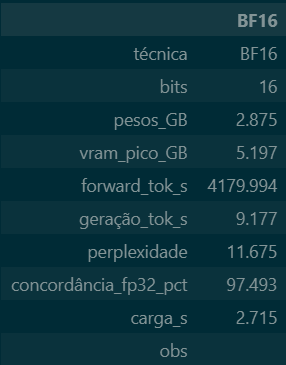

A perplexidade é 11,675 (+0,09% sobre o FP32) e a concordância top-1, 97,5%, abaixo dos 99,7% do FP16. Com só 7 bits de mantissa, o BF16 arredonda mais que o FP16, mas a perda continua desprezível, e ele não corre risco de estouro.

---
# Parte 2 — Inteiros de 8 bits

**Quantização** mapeia pesos em ponto flutuante para **inteiros** usando uma **escala** (e, opcionalmente, um deslocamento). Diferente da Parte 1, aqui há um mapeamento explícito, e é preciso guardar a escala para desquantizar.

**Zero-point (assimétrico):** usa toda a faixa $[\min, \max]$ do tensor.

$$s = \frac{255}{\max - \min} \qquad z = -\text{round}(s\cdot\min) - 128 \qquad q = \text{round}(s\cdot x + z)$$

**Absmax (simétrico):** usa o maior valor absoluto, centrado em zero.

$$s = \frac{127}{\max|x|} \qquad q = \text{round}(s\cdot x)$$

Em ambos os casos, $\hat{x} = (q - z)/s$ (com $z = 0$ no absmax) é próximo, mas **não idêntico**, ao valor original.

In [ ]:
# Mesmo cenário do capítulo: tensor com mínimo -4.0 e máximo 4.1; peso de valor 0.2.
x_min, x_max, w = -4.0, 4.1, 0.2

s_zp = 255 / (x_max - x_min)
z    = -np.round(s_zp * x_min) - 128
q_zp = np.clip(np.round(s_zp * w + z), -128, 127)

s_ab = 127 / max(abs(x_min), abs(x_max))
q_ab = np.clip(np.round(s_ab * w), -127, 127)

display(pd.DataFrame({
    "escala": [s_zp, s_ab], "zero-point": [z, 0],
    "INT8": [int(q_zp), int(q_ab)],
    "desquantizado": [(q_zp - z) / s_zp, q_ab / s_ab],
}, index=["Zero-point", "Absmax"]).round(4))

,escala,zero-point,INT8,desquantizado
Zero-point,31.4815,-2.0,4,0.1906
Absmax,30.9756,0.0,6,0.1937


### O problema dos *outliers* e por que quantizar em blocos

Com **uma escala por tensor**, um único valor atípico define o $\max|x|$ e "achata" todos os outros: eles passam a usar poucos dos 255 níveis disponíveis. A solução usada pelas técnicas a seguir é dar **uma escala por bloco** (linha, coluna ou grupo de poucos pesos), de modo que o *outlier* só prejudique o próprio bloco.

In [ ]:
torch.manual_seed(0)
pesos = torch.randn(4096) * 0.02          # distribuição típica de pesos
pesos_out = pesos.clone()
pesos_out[0] = 2.0                        # um único outlier, 100x maior que o desvio padrão

def absmax_tensor(t):
    s = 127 / t.abs().max()
    q = torch.round(t * s)
    return q / s, torch.unique(q).numel()

def absmax_blocos(t, bloco=64):
    tb = t.view(-1, bloco)
    s = 127 / tb.abs().amax(1, keepdim=True)
    q = torch.round(tb * s)
    return (q / s).view(-1), torch.unique(q).numel()

linhas = []
for nome_t, t in [("sem outlier", pesos), ("com 1 outlier", pesos_out)]:
    for nome_e, f in [("por tensor", absmax_tensor), ("blocos de 64", absmax_blocos)]:
        rec, niveis = f(t)
        erro = torch.mean((t[1:] - rec[1:]) ** 2).item()   # erro nos pesos normais (exclui o outlier)
        linhas.append({"tensor": nome_t, "escala": nome_e, "níveis INT8 usados": niveis, "MSE": erro})
display(pd.DataFrame(linhas).set_index(["tensor", "escala"]))

níveis INT8 usados           MSE
tensor        escala                                        
sem outlier   por tensor                   187  3.520825e-08
              blocos de 64                 246  1.512372e-08
com 1 outlier por tensor                    12  2.070059e-05
              blocos de 64                 246  3.395952e-07

### LLM.int8() (`bitsandbytes`)

Em LLMs, *outliers* sistemáticos aparecem nas **ativações**. O LLM.int8() ([arXiv:2208.07339](https://arxiv.org/abs/2208.07339)) combina escala por vetor com **precisão mista**: as colunas com *outliers* são multiplicadas em FP16 e o restante em INT8; os dois resultados são somados.

**Quando usar:** para fazer um modelo caber numa GPU com ≈ metade da memória do FP16, com perda mínima de qualidade, sem calibração.

> **Hipótese.** A perda de qualidade deve ser pequena, porque o caminho em FP16 protege os *outliers*. A geração deve ficar **mais lenta** que no FP16, apesar de ler metade dos bytes, por causa do trabalho extra de separar e recombinar as colunas.

In [ ]:
cfg_int8 = BitsAndBytesConfig(load_in_8bit=True)

rodar("INT8 (LLM.int8)",
      lambda: AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=cfg_int8,
                                                   dtype=torch.float16, device_map={"": 0}),
      bits=8)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,INT8 (LLM.int8)
técnica,INT8 (LLM.int8)
bits,8
pesos_GB,1.655
vram_pico_GB,3.976
forward_tok_s,4157.571
geração_tok_s,6.05
geração_tok_s_min,5.992
geração_tok_s_max,6.133
perplexidade,11.751
concordância_fp32_pct,95.658


HellaSwag acc_norm: 67.8% (500 exemplos)
Geração por lote (tok/s): 1: 6.0, 8: 47.8, 32: 183.5
Texto gerado:  in the 1950s, when researchers first started to explore how computers could be programmed to perform tasks that were traditionally done by humans. Since then, AI has come a long way and is now used i ...


### Resultado da Parte 2

**Hipótese confirmada nos dois pontos.**

- **Qualidade:** +0,74% de perplexidade (IC 95% [+0,52%; +0,96%]). A perda é pequena, mas real, porque o intervalo não inclui zero. No HellaSwag, 67,8% (+0,2 ponto percentual, IC [−1,0; +1,6]), sem perda detectável. A concordância top-1 cai para 95,7%: o token mais provável muda em ~4% das posições, sem efeito mensurável na tarefa.
- **Memória:** 1,66 GiB, 1,7× menos que o FP16, e não 2×. A matriz de *embedding* continua em 16 bits, e a média fica em 9,2 bits por peso.
- **Velocidade:** a geração é 4,2× mais lenta que a do FP16 com lote 1 (6,0 contra 25,7 tok/s), e a razão se mantém nos lotes 8 e 32 (Parte 5). O custo é da técnica, não um efeito do lote pequeno. No *forward*, a perda é de só 9% (4.158 contra 4.584 tok/s), provavelmente porque o trabalho extra pesa menos quando cada chamada processa muitos tokens.

---
# Parte 3 — 4 bits em GPU: NF4 e GPTQ

| | **NF4** (`bitsandbytes`) | **GPTQ** |
|---|---|---|
| Quando quantiza | No carregamento, em segundos | *Offline*, uma única vez (minutos a horas) |
| Calibração | Não precisa | Precisa de amostras de texto |
| Como escolhe os valores | 16 níveis distribuídos como uma normal, escala por bloco de 64 | Ajusta os pesos de cada camada para compensar o erro, usando informação de 2ª ordem ([arXiv:2210.17323](https://arxiv.org/abs/2210.17323)) |
| Distribuição | Quantiza o checkpoint original | Checkpoint já quantizado no Hub |

Parâmetros do checkpoint GPTQ usado: `bits=4`, `group_size=128` (uma escala a cada 128 pesos), `desc_act=False`, `sym=True`.

**Quando usar:** **NF4** para experimentar rápido ou fazer *fine-tuning* (QLoRA) com pouca memória. **GPTQ** para servir em GPU quando já existe (ou vale gerar) um checkpoint quantizado e o motor de inferência tem kernels otimizados para ele.

> **Hipótese.** As duas técnicas devem ocupar memória parecida. Como o GPTQ usa calibração e compensa o erro de cada camada, esperamos que ele seja **mais fiel** ao FP32 que o NF4, que só arredonda. Na velocidade, esperamos que os dois gerem mais rápido que o FP16, por lerem menos bytes, com vantagem para o GPTQ, que usa kernels dedicados (ExLlamaV2).

In [ ]:
cfg_nf4 = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_compute_dtype=torch.float16)

rodar("NF4 (bnb 4-bit)",
      lambda: AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=cfg_nf4,
                                                   dtype=torch.float16, device_map={"": 0}),
      bits=4)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,NF4 (bnb 4-bit)
técnica,NF4 (bnb 4-bit)
bits,4
pesos_GB,1.045
vram_pico_GB,3.445
forward_tok_s,3937.859
geração_tok_s,18.304
geração_tok_s_min,18.225
geração_tok_s_max,19.937
perplexidade,12.789
concordância_fp32_pct,84.295


HellaSwag acc_norm: 66.8% (500 exemplos)
Geração por lote (tok/s): 1: 19.2, 8: 133.4, 32: 566.8
Texto gerado:  with the invention of the first computer in 1946. The term "artificial intelligence" was coined by John McCarthy, who founded the field and developed the rule-based system MYCIN to detect infections  ...


In [ ]:
import sys, logging, contextlib
import transformers

# Silencia os avisos do transformers/accelerate (ex.: "model weights are not tied").
transformers.logging.set_verbosity_error()
logging.getLogger("accelerate").setLevel(logging.ERROR)

LOG_GPTQ = os.path.join(OUT_DIR, "gptq_load.log")
_arquivo_log = open(LOG_GPTQ, "a", buffering=1)      # fica aberto durante toda a sessão

@contextlib.contextmanager
def silenciar():
    # Desvia para LOG_GPTQ a saída do Python e também a de processos externos (nvcc, ninja),
    # que escrevem direto nos descritores 1 e 2 do sistema operacional.
    sys.stdout.flush(); sys.stderr.flush()
    fd_out, fd_err = os.dup(1), os.dup(2)
    os.dup2(_arquivo_log.fileno(), 1)
    os.dup2(_arquivo_log.fileno(), 2)
    try:
        with contextlib.redirect_stdout(_arquivo_log), contextlib.redirect_stderr(_arquivo_log):
            yield
    finally:
        _arquivo_log.flush()
        os.dup2(fd_out, 1); os.dup2(fd_err, 2)
        os.close(fd_out); os.close(fd_err)

# Importar dentro do bloco faz o logger do GPTQModel já nascer apontando para o arquivo.
with silenciar():
    from gptqmodel import GPTQModel, BACKEND

# Ordem de preferência na T4. O Marlin fica de fora: o build dele falha no Colab.
BACKENDS_T4 = [getattr(BACKEND, n) for n in ("EXLLAMA_V2", "TRITON", "TORCH") if hasattr(BACKEND, n)]

def carregar_gptq():
    for backend in BACKENDS_T4:
        nome_b = getattr(backend, "name", str(backend))
        try:
            with silenciar():
            ##################################################################
                gm = GPTQModel.load(GPTQ_ID, backend=backend)

            model = gm.model                                   # modelo do transformers

            ##################################################################

            kernels = sorted({type(m).__name__ for m in model.modules()
                              if type(m).__module__.startswith("gptqmodel") and "Linear" in type(m).__name__})
            print(f"GPTQ carregado: backend={nome_b}, kernel={', '.join(kernels)}")
            return model, f"kernel={'/'.join(kernels)}"
        except Exception as e:
            primeira_linha = str(e).splitlines()[0][:150] if str(e) else ""
            print(f"Falha com {nome_b}: {type(e).__name__}: {primeira_linha}")
            liberar_memoria()
    raise RuntimeError(f"Não foi possível carregar o modelo GPTQ (log completo em {LOG_GPTQ}).")

rodar("GPTQ 4-bit", carregar_gptq, bits=4)

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

GPTQ carregado: backend=EXLLAMA_V2, kernel=ExllamaV2Linear


,GPTQ 4-bit
técnica,GPTQ 4-bit
bits,4
pesos_GB,1.071
vram_pico_GB,3.387
forward_tok_s,4021.441
geração_tok_s,18.187
geração_tok_s_min,17.588
geração_tok_s_max,18.775
perplexidade,13.322
concordância_fp32_pct,82.761


HellaSwag acc_norm: 67.0% (500 exemplos)
Geração por lote (tok/s): 1: 18.2, 8: 152.7, 32: 528.7
Texto gerado:  in the 1950s, when researchers first started to explore how computers could be used to solve problems that humans found difficult. Since then, AI has made significant progress and is now being applie ...


### Resultado da Parte 3

**Memória: confirmada.** NF4 ocupa 1,05 GiB e GPTQ 1,07 GiB, ~2,7× menos que o FP16. A média real fica em ~5,8–6,0 bits por peso, e não em 4: a matriz de *embedding* (≈ 233 milhões de parâmetros, compartilhada com a camada de saída) continua em 16 bits e, sozinha, ocupa ~0,43 GiB, cerca de 40% do total. Em modelos pequenos com vocabulário grande (152 mil tokens no Qwen2.5), esse limite pesa mais.

**Qualidade: hipótese refutada na perplexidade.** O GPTQ ficou **pior** que o NF4: +14,2% contra +9,6% sobre o FP32. A diferença entre os dois (+4,2%, IC 95% [+2,8%; +5,7%]) aparece em 100% dos sorteios do bootstrap, e a concordância top-1 também é menor (82,8% contra 84,3%). Há três explicações possíveis, não testadas aqui:

- **Granularidade:** o NF4 usa uma escala a cada 64 pesos; o GPTQ, a cada 128.
- **Configuração conservadora:** o checkpoint usa `desc_act=False`, que não quantiza as colunas em ordem de importância (isso simplifica os kernels, mas abre mão de parte da precisão do GPTQ), e `sym=True`, uma grade simétrica que desperdiça níveis quando a distribuição dos pesos não é centrada.
- **Domínio da calibração:** o GPTQ é calibrado num conjunto de textos que pode diferir do WikiText, e a perplexidade aqui mede a fidelidade justamente nesse domínio.

No **HellaSwag**, nenhum dos dois perde de forma detectável (NF4 −0,8 e GPTQ −0,6 ponto percentual, ambos com IC incluindo zero), e a ordem entre eles se inverte, dentro do ruído.

**Velocidade: refutada.** Os dois geram ~18 tok/s com lote 1, cerca de 0,7× o FP16, e nenhum supera o outro. Ler menos bytes não compensou o custo de desquantizar (ver Parte 5). A carga do GPTQ (153 s) inclui o download e a preparação dos kernels, e só acontece uma vez por sessão.

---
# Parte 4 — 4 bits em CPU: GGUF (llama.cpp)

O **GGUF** é o formato do ecossistema **llama.cpp**: um único arquivo com pesos quantizados, metadados e tokenizador, pronto para rodar em CPU (x86, Apple Silicon, Android), sem PyTorch.

Os pesos são quantizados em **blocos pequenos**, cada um com a própria escala, o mesmo princípio da Parte 2. O nome do arquivo indica o esquema: em `Q4_K_M`, **Q4** são 4 bits por peso, **K** indica *K-quants* (blocos hierárquicos cujas escalas também são quantizadas) e **M** o tamanho do *mix* (S/M/L), que mantém as camadas mais sensíveis com mais bits.

**Por que `bits_por_peso` fica acima do nominal.** A coluna é o tamanho real do arquivo dividido pelo número de parâmetros do modelo. Há dois motivos para ela superar o valor do nome:

- o *mix* dos K-quants guarda algumas camadas com mais bits;
- o Qwen2.5-1.5B **compartilha** a matriz de *embedding* com a camada de saída (*tied embeddings*), mas o arquivo GGUF guarda essa matriz **duas vezes**, enquanto a contagem de parâmetros a inclui uma vez só. São ~233 milhões de parâmetros a mais no numerador.

No Q8_0 (nominal ≈ 8,5 bits), a conta fecha: a cópia extra soma ≈ 0,25 GB, praticamente a diferença entre o tamanho nominal (≈ 1,64 GB) e o arquivo (1,89 GB, que aparece como 1,76 porque as tabelas usam GiB, 2³⁰ bytes). Daí os 9,8 bits por peso.

**Quando usar:** execução local ou em servidores sem GPU. O nível é escolhido pelo orçamento de memória: Q8_0 é praticamente sem perda; Q4_K_M costuma ser o melhor equilíbrio; Q2_K só quando a memória é crítica.

> Por limite de tempo na CPU do Colab, a perplexidade aqui usa as **4 primeiras janelas** do mesmo conjunto. A referência FP16 é recalculada nas mesmas 4 janelas para a comparação ser justa. Os tokens/s de CPU não são comparáveis aos da GPU.

> **Hipótese.** O Q8_0 deve ser praticamente sem perda, o Q4_K_M deve perder algo próximo do NF4 (os dois usam ~4 bits com blocos pequenos) e o Q2_K deve perder muito. Na CPU, que não tem o *overhead* de lançar kernels na GPU, esperamos que arquivos menores gerem mais rápido.

In [ ]:
from llama_cpp import Llama
from huggingface_hub import hf_hub_download, model_info

NIVEIS = {
    "Q8_0":   "qwen2.5-1.5b-instruct-q8_0.gguf",
    "Q5_K_M": "qwen2.5-1.5b-instruct-q5_k_m.gguf",
    "Q4_K_M": "qwen2.5-1.5b-instruct-q4_k_m.gguf",
    "Q2_K":   "qwen2.5-1.5b-instruct-q2_k.gguf",
}
try:
    N_PARAMS = model_info(MODEL_ID).safetensors.total
except Exception:
    N_PARAMS = 1_543_714_304

ids_cpu = ids[:N_WIN_GGUF].numpy()

def nll_janela(llm, janela):
    # Mesma conta do eval_forward: NLL de prever os tokens 1..511 a partir dos anteriores.
    llm.reset()
    llm.eval(janela.tolist())                         # usa os mesmos IDs de token do transformers
    lg = np.asarray(llm.scores[: len(janela)], dtype=np.float32)[:-1]
    m = lg.max(-1)
    lse = m + np.log(np.exp(lg - m[:, None]).sum(-1))
    return float((lse - lg[np.arange(len(janela) - 1), janela[1:]]).sum())

for nivel, arquivo in NIVEIS.items():
    caminho = hf_hub_download(GGUF_REPO, arquivo)


    #######################################################################
    llm = Llama(model_path=caminho, n_ctx=SEQ_LEN, logits_all=True, n_gpu_layers=0,
                n_threads=os.cpu_count(), seed=SEED, verbose=False)
    #######################################################################

    t0 = time.perf_counter()
    nll = np.array([nll_janela(llm, w) for w in ids_cpu])
    fwd_tps = ids_cpu.size / (time.perf_counter() - t0)
    ppl = float(np.exp(nll.sum() / (N_WIN_GGUF * (SEQ_LEN - 1))))
    np.save(os.path.join(OUT_DIR, f"nll_{slug('GGUF ' + nivel)}.npy"), nll)   # NLL por janela, como na GPU

    llm.reset()
    llm.create_completion(PROMPT, max_tokens=8, temperature=0.0)        # aquecimento
    llm.reset()
    t0 = time.perf_counter()
    saida = llm.create_completion(PROMPT, max_tokens=GEN_TOKENS, temperature=0.0)
    dt = time.perf_counter() - t0
    n_gerados = saida["usage"]["completion_tokens"]

    tamanho = os.path.getsize(caminho)
    linha = {"técnica": f"GGUF {nivel}", "bits_por_peso": tamanho * 8 / N_PARAMS,
             "arquivo_GB": tamanho / 2**30, "forward_tok_s": fwd_tps, "geração_tok_s": n_gerados / dt,
             "perplexidade": ppl, "texto_gerado": saida["choices"][0]["text"]}
    salvar_linha(linha, CSV_GGUF)
    print(f"{nivel:7s} | {linha['arquivo_GB']:.2f} GB | {linha['bits_por_peso']:.2f} bits/peso | "
          f"forward {fwd_tps:6.1f} tok/s | geração {linha['geração_tok_s']:5.1f} tok/s | PPL {ppl:.3f}")
    del llm
    gc.collect()

qwen2.5-1.5b-instruct-q8_0.gguf: reconstructing file:   0%|          |  0.00B / 1.89GB            

qwen2.5-1.5b-instruct-q8_0.gguf: downloading bytes:           |  0.00B            

Q8_0    | 1.76 GB | 9.82 bits/peso | forward   10.8 tok/s | geração   4.8 tok/s | PPL 12.963


qwen2.5-1.5b-instruct-q5_k_m.gguf: reconstructing file:   0%|          |  0.00B / 1.29GB            

qwen2.5-1.5b-instruct-q5_k_m.gguf: downloading bytes:           |  0.00B            

Q5_K_M  | 1.20 GB | 6.66 bits/peso | forward   16.5 tok/s | geração   5.3 tok/s | PPL 13.023


... (2 outputs left out)

Q4_K_M  | 1.04 GB | 5.79 bits/peso | forward   15.6 tok/s | geração   7.3 tok/s | PPL 13.966


qwen2.5-1.5b-instruct-q2_k.gguf: reconstructing file:   0%|          |  0.00B /  753MB            

qwen2.5-1.5b-instruct-q2_k.gguf: downloading bytes:           |  0.00B            

Q2_K    | 0.70 GB | 3.90 bits/peso | forward   15.6 tok/s | geração   6.8 tok/s | PPL 22.696


Referência FP16 nas mesmas 4 janelas: PPL = 12.745


,bits_por_peso,arquivo_GB,forward_tok_s,geração_tok_s,perplexidade,Δppl_vs_fp16_%
técnica,,,,,,
GGUF Q8_0,9.818,1.764,10.835,4.812,12.963,1.709
GGUF Q5_K_M,6.662,1.197,16.484,5.275,13.023,2.185
GGUF Q4_K_M,5.790,1.041,15.645,7.333,13.966,9.582
GGUF Q2_K,3.902,0.701,15.602,6.845,22.696,78.075


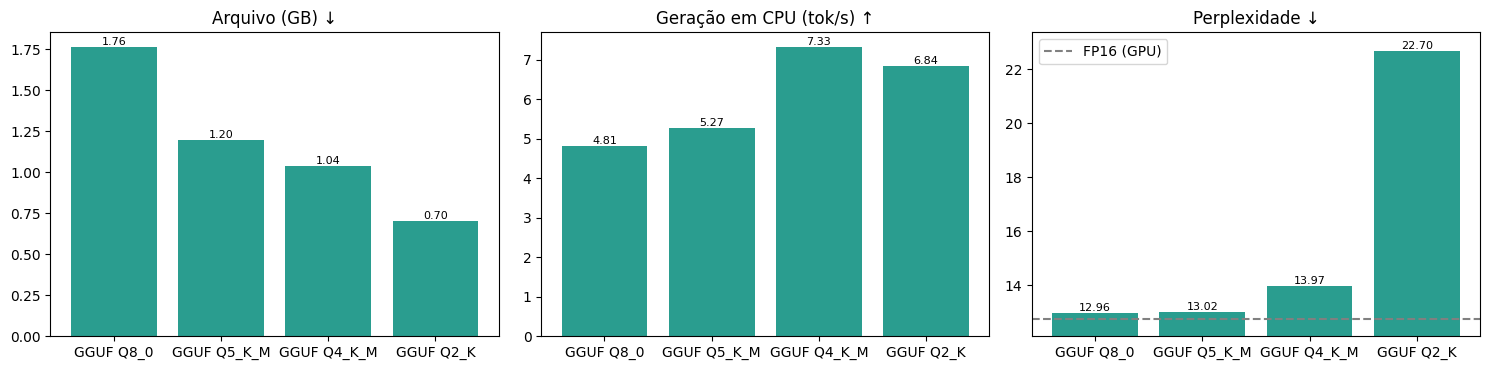

In [ ]:
# GGUF em CPU, comparado à referência FP16 (GPU) calculada nas mesmas janelas.
dg = pd.read_csv(CSV_GGUF).set_index("técnica")
ref_path = os.path.join(OUT_DIR, "nll_FP16.npy")
ppl_ref = float(np.exp(np.load(ref_path)[:N_WIN_GGUF].sum() / (N_WIN_GGUF * (SEQ_LEN - 1)))) \
          if os.path.exists(ref_path) else float("nan")
dg["Δppl_vs_fp16_%"] = (dg["perplexidade"] / ppl_ref - 1) * 100
print(f"Referência FP16 nas mesmas {N_WIN_GGUF} janelas: PPL = {ppl_ref:.3f}")
display(dg.drop(columns="texto_gerado").round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, titulo) in zip(axes, [("arquivo_GB", "Arquivo (GB) ↓"), ("geração_tok_s", "Geração em CPU (tok/s) ↑"),
                                    ("perplexidade", "Perplexidade ↓")]):
    barras = ax.bar(dg.index, dg[col], color="#2a9d8f")
    ax.bar_label(barras, fmt="%.2f", fontsize=8)
    ax.set_title(titulo)
    if col == "perplexidade":
        if np.isfinite(ppl_ref):
            ax.axhline(ppl_ref, ls="--", color="gray", label="FP16 (GPU)")
            ax.legend()
        ax.set_ylim(np.nanmin([dg[col].min(), ppl_ref]) * 0.95, dg[col].max() * 1.03)
plt.tight_layout(); plt.show()

### Resultado da Parte 4

**Qualidade: confirmada.** Contra o FP16 nas mesmas 4 janelas, o Q8_0 perde 1,7%, o Q5_K_M 2,2%, o Q4_K_M 9,6% e o Q2_K 78%. Nas mesmas 4 janelas, os métodos da GPU ficam assim (coluna `Δppl_4jan_%` da Parte 5): INT8 +1,2%, NF4 +7,2% e GPTQ +13,9%. Ou seja, o Q8_0 fica perto do INT8, e o Q4_K_M, entre os dois métodos de 4 bits da GPU. Com só 4 janelas (~2 mil tokens), diferenças de 1 ou 2 pontos percentuais estão dentro do ruído.

O Q5_K_M merece atenção: com 15% mais memória que o Q4_K_M, perde quatro vezes menos perplexidade.

**Velocidade: confirmada.** Na CPU, menos bits significou mais velocidade: o Q4_K_M gera 7,3 tok/s, 1,5× o Q8_0 (4,8 tok/s). Tudo indica que aqui a leitura dos pesos da RAM é de fato o gargalo, e o llama.cpp tem kernels otimizados para cada formato. O Q2_K (6,8 tok/s) não supera o Q4_K_M: abaixo de certo ponto, desempacotar os bits custa mais do que se economiza na leitura. Cada geração foi medida uma única vez, então diferenças pequenas de velocidade não são conclusivas.

---
# Parte 5 — Síntese

Esta parte não carrega modelos: lê o que foi gravado em `resultados/` e responde à pergunta da apresentação em quatro passos.

1. **Incerteza:** quais diferenças de qualidade são maiores que o ruído (bootstrap pareado).
2. **Tabela única:** GPU e CPU lado a lado, com qualidade e custo separados.
3. **Custo × qualidade:** a fronteira de Pareto, que indica o que escolher para cada orçamento de memória.
4. **Tamanho de lote:** quando (e se) a quantização acelera a geração.

In [ ]:
# Intervalos de confiança por bootstrap pareado. A cada sorteio, as MESMAS janelas (ou exemplos)
# são usadas para todas as técnicas: a variação de dificuldade entre janelas afeta todas igualmente
# e se cancela nas comparações, o que deixa os intervalos das diferenças bem mais estreitos.
ORDEM  = ["FP32", "FP16", "BF16", "INT8 (LLM.int8)", "NF4 (bnb 4-bit)", "GPTQ 4-bit"]
N_BOOT = 10_000

def bootstrap_pareado(matriz, estatistica, n_boot=N_BOOT, seed=SEED, bloco=1000):
    # matriz: (n_amostras, n_técnicas). Sorteia linhas com reposição e aplica `estatistica`
    # a cada reamostra (n_amostras, n_técnicas). Retorna (n_boot, n_técnicas).
    rng = np.random.default_rng(seed)
    saida = []
    for i in range(0, n_boot, bloco):                  # em blocos, para limitar a memória
        idx = rng.integers(0, len(matriz), size=(min(bloco, n_boot - i), len(matriz)))
        saida.append(estatistica(matriz[idx]))
    return np.concatenate(saida)

def ic95(amostras):
    return np.percentile(amostras, [2.5, 97.5], axis=0)

def caminho_npy(prefixo, tecnica):
    return os.path.join(OUT_DIR, f"{prefixo}_{slug(tecnica)}.npy")

medidas = pd.read_csv(CSV_GPU)["técnica"].tolist()
tec_ppl = [t for t in ORDEM if t in medidas and os.path.exists(caminho_npy("nll", t))]
REF = "FP32" if "FP32" in tec_ppl else tec_ppl[0]       # referência de todas as comparações

# --- Perplexidade: NLL por janela, (32 janelas, técnicas) ---
NLL = np.column_stack([np.load(caminho_npy("nll", t)) for t in tec_ppl])
ppl = lambda m: np.exp(m.sum(-2) / (m.shape[-2] * (SEQ_LEN - 1)))
ppl_boot = bootstrap_pareado(NLL, ppl)
dppl_boot = (ppl_boot / ppl_boot[:, [tec_ppl.index(REF)]] - 1) * 100

ic = pd.DataFrame(index=tec_ppl)
ic["perplexidade"] = ppl(NLL)
ic["ppl_ic_inf"], ic["ppl_ic_sup"] = ic95(ppl_boot)
ic["Δppl_%"] = (ic["perplexidade"] / ic.loc[REF, "perplexidade"] - 1) * 100
ic["Δppl_ic_inf"], ic["Δppl_ic_sup"] = ic95(dppl_boot)

# --- HellaSwag: acerto (acc_norm) por exemplo, (exemplos, técnicas) ---
tec_hs = [t for t in tec_ppl if os.path.exists(caminho_npy("hellaswag", t))]
if tec_hs:
    ACE = np.column_stack([np.load(caminho_npy("hellaswag", t))[:, 1] for t in tec_hs]).astype(np.float32)
    acc_boot = bootstrap_pareado(ACE, lambda m: m.mean(-2) * 100)
    ic.loc[tec_hs, "acc_norm_%"] = ACE.mean(0) * 100
    ic.loc[tec_hs, "acc_ic_inf"], ic.loc[tec_hs, "acc_ic_sup"] = ic95(acc_boot)
    if REF in tec_hs:
        dacc_boot = acc_boot - acc_boot[:, [tec_hs.index(REF)]]
        ic.loc[tec_hs, "Δacc_pp"] = ic.loc[tec_hs, "acc_norm_%"] - ic.loc[REF, "acc_norm_%"]
        ic.loc[tec_hs, "Δacc_ic_inf"], ic.loc[tec_hs, "Δacc_ic_sup"] = ic95(dacc_boot)

print(f"IC de 95% por bootstrap pareado ({N_BOOT} sorteios); referência: {REF}. "
      f"Perplexidade em {NLL.shape[0]} janelas" + (f", HellaSwag em {ACE.shape[0]} exemplos." if tec_hs else "."))
display(ic.round(2))

# --- Comparações diretas entre pares: a diferença é maior que o ruído? ---
COMPARACOES = [("FP16", "FP32"), ("INT8 (LLM.int8)", "FP16"), ("NF4 (bnb 4-bit)", "FP16"),
               ("GPTQ 4-bit", "NF4 (bnb 4-bit)")]
linhas = []
for a, b in COMPARACOES:
    if a not in tec_ppl or b not in tec_ppl:
        continue
    d = (ppl_boot[:, tec_ppl.index(a)] / ppl_boot[:, tec_ppl.index(b)] - 1) * 100
    lin = {"comparação": f"{a}  vs  {b}",
           "Δppl_%": (ic.loc[a, "perplexidade"] / ic.loc[b, "perplexidade"] - 1) * 100,
           "Δppl_IC95": f"[{np.percentile(d, 2.5):+.2f}; {np.percentile(d, 97.5):+.2f}]",
           "% sorteios com A pior (ppl)": (d > 0).mean() * 100}
    if a in tec_hs and b in tec_hs:
        da = acc_boot[:, tec_hs.index(a)] - acc_boot[:, tec_hs.index(b)]
        lin["Δacc_pp"] = ACE[:, tec_hs.index(a)].mean() * 100 - ACE[:, tec_hs.index(b)].mean() * 100
        lin["Δacc_IC95"] = f"[{np.percentile(da, 2.5):+.1f}; {np.percentile(da, 97.5):+.1f}]"
    linhas.append(lin)
comparacoes = pd.DataFrame(linhas).set_index("comparação")      # leitura: A  vs  B
display(comparacoes.round(2))
print("Um IC que não contém zero indica diferença maior que a variação entre janelas (ou exemplos).")

IC de 95% por bootstrap pareado (10000 sorteios); referência: FP32. Perplexidade em 32 janelas, HellaSwag em 500 exemplos.


,perplexidade,ppl_ic_inf,ppl_ic_sup,Δppl_%,Δppl_ic_inf,Δppl_ic_sup,acc_norm_%,acc_ic_inf,acc_ic_sup,Δacc_pp,Δacc_ic_inf,Δacc_ic_sup
FP32,11.66,10.08,13.34,0.00,0.00,0.00,67.599998,63.4,71.80,0.0,0.0,0.0
FP16,11.66,10.08,13.34,-0.01,-0.02,0.00,67.599998,63.4,71.80,0.0,0.0,0.0
INT8 (LLM.int8),11.75,10.16,13.43,0.74,0.52,0.96,67.800003,63.6,71.81,0.2,-1.0,1.6
NF4 (bnb 4-bit),12.79,11.07,14.63,9.64,8.29,10.97,66.800003,62.6,70.80,-0.8,-2.8,1.2
GPTQ 4-bit,13.32,11.52,15.22,14.21,12.99,15.48,67.000000,62.8,71.20,-0.6,-2.2,1.0


,Δppl_%,Δppl_IC95,% sorteios com A pior (ppl),Δacc_pp,Δacc_IC95
comparação,,,,,
FP16 vs FP32,-0.01,[-0.02; +0.00],2.94,0.0,[+0.0; +0.0]
INT8 (LLM.int8) vs FP16,0.75,[+0.53; +0.97],100.00,0.2,[-1.0; +1.6]
NF4 (bnb 4-bit) vs FP16,9.65,[+8.30; +10.99],100.00,-0.8,[-2.8; +1.2]
GPTQ 4-bit vs NF4 (bnb 4-bit),4.17,[+2.79; +5.66],100.00,0.2,[-2.0; +2.4]


Um IC que não contém zero indica diferença maior que a variação entre janelas (ou exemplos).


### Leitura dos intervalos de confiança

**Perplexidade.** Os intervalos absolutos são largos (o do FP32 vai de 10,1 a 13,3) porque a dificuldade varia muito entre janelas. Mas essa variação atinge todas as técnicas igualmente, e os intervalos das **diferenças** são estreitos. Todas as diferenças de perplexidade são reais, inclusive a do INT8 (+0,7%) e a do GPTQ contra o NF4 (+4,2%). A exceção prática é FP16 contra FP32: −0,01%, sem importância.

**HellaSwag.** Nenhuma diferença se distingue do ruído: todos os intervalos das diferenças incluem zero. Com 500 questões, o teste detectaria perdas a partir de ~2 a 3 pontos percentuais; perdas menores não podem ser descartadas.

**O que isso significa.** Os 10–14% de perplexidade a mais nos métodos de 4 bits são uma piora real na distribuição de probabilidade do próximo token, mas não viraram erro numa tarefa de múltipla escolha de senso comum. As duas métricas medem coisas diferentes:

- a perplexidade pesa cada token do texto, inclusive nomes, datas e detalhes raros;
- a múltipla escolha só pergunta se a opção certa ficou acima das outras três.

Uma perda de perplexidade desse tamanho pode aparecer em tarefas que dependem de detalhes factuais ou de textos longos (veja a saída qualitativa no fim desta parte). Por isso, a decisão final deve vir de uma avaliação na tarefa real de quem vai usar o modelo.

In [ ]:
# Tabela única com GPU e CPU (GGUF). Cada Δ de perplexidade é calculado contra a referência nas
# MESMAS janelas: 32 para a GPU e 4 para o GGUF. A coluna "Δppl_4jan_%" recalcula todas as linhas
# nas 4 primeiras janelas, o que põe GPU e CPU na mesma base (com mais ruído).
if "N_PARAMS" not in globals():
    try:
        from huggingface_hub import model_info
        N_PARAMS = model_info(MODEL_ID).safetensors.total
    except Exception:
        N_PARAMS = 1_543_714_304

def ppl_janelas(tecnica, n):
    nll = np.load(caminho_npy("nll", tecnica))[:n]
    return float(np.exp(nll.sum() / (n * (SEQ_LEN - 1))))

gpu = pd.read_csv(CSV_GPU).set_index("técnica")
gpu = gpu.loc[[t for t in ORDEM if t in gpu.index]]
ppl_ref4 = ppl_janelas(REF, N_WIN_GGUF)

linhas = []
for t, r in gpu.iterrows():
    tem_nll = os.path.exists(caminho_npy("nll", t))
    linhas.append({"técnica": t, "plataforma": "GPU", "janelas": N_WINDOWS,
                   "bits_por_peso": r["pesos_GB"] * 2**30 * 8 / N_PARAMS, "memória_GB": r["pesos_GB"],
                   "vram_pico_GB": r["vram_pico_GB"], "forward_tok_s": r["forward_tok_s"],
                   "geração_tok_s": r["geração_tok_s"], "perplexidade": r["perplexidade"],
                   "Δppl_%": (r["perplexidade"] / gpu.loc[REF, "perplexidade"] - 1) * 100,
                   "Δppl_4jan_%": (ppl_janelas(t, N_WIN_GGUF) / ppl_ref4 - 1) * 100 if tem_nll else np.nan,
                   "concordância_fp32_pct": r["concordância_fp32_pct"]})
if os.path.exists(CSV_GGUF):
    for t, r in pd.read_csv(CSV_GGUF).set_index("técnica").iterrows():
        d = (r["perplexidade"] / ppl_ref4 - 1) * 100       # o GGUF já é medido nas 4 janelas
        linhas.append({"técnica": t, "plataforma": "CPU", "janelas": N_WIN_GGUF,
                       "bits_por_peso": r["bits_por_peso"], "memória_GB": r["arquivo_GB"],
                       "forward_tok_s": r["forward_tok_s"], "geração_tok_s": r["geração_tok_s"],
                       "perplexidade": r["perplexidade"], "Δppl_%": d, "Δppl_4jan_%": d})
sintese = pd.DataFrame(linhas).set_index("técnica")
sintese = sintese.join(ic.drop(columns=["perplexidade", "Δppl_%"]))

# Velocidade de geração com o maior lote da varredura (mediana das repetições).
if os.path.exists(CSV_LOTES):
    dl = pd.read_csv(CSV_LOTES)
    LOTE_MAX = int(dl["lote"].max())
    sintese[f"geração_lote{LOTE_MAX}_tok_s"] = dl[dl["lote"] == LOTE_MAX].groupby("técnica")["tok_s"].median()

def faixa(inf, sup, casas):
    return np.where(pd.notna(inf), [f"[{a:+.{casas}f}; {b:+.{casas}f}]" for a, b in zip(inf, sup)], "—")

sintese["Δppl_IC95"] = faixa(sintese.get("Δppl_ic_inf"), sintese.get("Δppl_ic_sup"), 1)
if "acc_norm_%" in sintese:
    sintese["acc_IC95"] = np.where(sintese["acc_norm_%"].notna(),
                                   [f"[{a:.1f}; {b:.1f}]" for a, b in zip(sintese["acc_ic_inf"], sintese["acc_ic_sup"])], "—")

def destacar_cpu(linha):
    cor = "background-color: rgba(231, 111, 81, 0.18)" if sintese.loc[linha.name, "plataforma"] == "CPU" else ""
    return [cor] * len(linha)

def mostrar(colunas, legenda):
    cols = [c for c in colunas if c in sintese.columns]
    display(sintese[cols].style.apply(destacar_cpu, axis=1)
            .format(precision=2, na_rep="—").set_caption(legenda))

mostrar(["plataforma", "janelas", "perplexidade", "Δppl_%", "Δppl_IC95", "Δppl_4jan_%",
         "concordância_fp32_pct", "acc_norm_%", "acc_IC95"],
        f"QUALIDADE (Δ contra {REF} nas mesmas janelas). ⚠ Linhas destacadas = GGUF em CPU: perplexidade "
        f"em só {N_WIN_GGUF} janelas, sem IC e sem HellaSwag. Para comparar GPU e CPU, use Δppl_4jan_%.")
mostrar(["plataforma", "bits_por_peso", "memória_GB", "vram_pico_GB", "forward_tok_s", "geração_tok_s",
         f"geração_lote{LOTE_MAX}_tok_s" if os.path.exists(CSV_LOTES) else ""],
        "CUSTO (memória em GiB; bits_por_peso = tamanho real ÷ nº de parâmetros). "
        "⚠ Os tok/s das linhas destacadas são de CPU e não se comparam aos da GPU.")

,plataforma,janelas,perplexidade,Δppl_%,Δppl_IC95,Δppl_4jan_%,concordância_fp32_pct,acc_norm_%,acc_IC95
técnica,,,,,,,,,
FP32,GPU,32,11.66,0.00,[+0.0; +0.0],0.00,100.00,67.60,[63.4; 71.8]
FP16,GPU,32,11.66,-0.01,[-0.0; +0.0],0.01,99.68,67.60,[63.4; 71.8]
INT8 (LLM.int8),GPU,32,11.75,0.74,[+0.5; +1.0],1.19,95.66,67.80,[63.6; 71.8]
NF4 (bnb 4-bit),GPU,32,12.79,9.64,[+8.3; +11.0],7.21,84.30,66.80,[62.6; 70.8]
GPTQ 4-bit,GPU,32,13.32,14.21,[+13.0; +15.5],13.90,82.76,67.00,[62.8; 71.2]
GGUF Q8_0,CPU,4,12.96,1.72,—,1.72,—,—,—
GGUF Q5_K_M,CPU,4,13.02,2.19,—,2.19,—,—,—
GGUF Q4_K_M,CPU,4,13.97,9.59,—,9.59,—,—,—
GGUF Q2_K,CPU,4,22.70,78.09,—,78.09,—,—,—


,plataforma,bits_por_peso,memória_GB,vram_pico_GB,forward_tok_s,geração_tok_s,geração_lote32_tok_s
técnica,,,,,,,
FP32,GPU,32.00,5.75,9.22,1233.40,28.72,505.68
FP16,GPU,16.00,2.88,5.19,4584.21,25.67,808.43
INT8 (LLM.int8),GPU,9.21,1.66,3.98,4157.57,6.05,183.46
NF4 (bnb 4-bit),GPU,5.82,1.05,3.44,3937.86,18.30,566.76
GPTQ 4-bit,GPU,5.96,1.07,3.39,4021.44,18.19,528.73
GGUF Q8_0,CPU,9.82,1.76,—,10.83,4.81,—
GGUF Q5_K_M,CPU,6.66,1.20,—,16.48,5.27,—
GGUF Q4_K_M,CPU,5.79,1.04,—,15.64,7.33,—
GGUF Q2_K,CPU,3.90,0.70,—,15.60,6.84,—


### Leitura da tabela única

- **Linhas destacadas** são os GGUF, medidos em CPU. A coluna `Δppl_%` compara cada técnica com o FP32 **nas mesmas janelas** (32 na GPU, 4 na CPU). Para comparar GPU e CPU, use `Δppl_4jan_%`, que recalcula todas as linhas nas 4 primeiras janelas.
- **Os "4 bits" ocupam o mesmo espaço.** NF4 (5,8), GPTQ (6,0) e Q4_K_M (5,8) têm praticamente os mesmos bits por peso reais. A diferença entre eles está na qualidade, não na compressão.
- **O pico de VRAM é bem maior que os pesos.** Ele é medido durante o *forward* em lotes de 4 janelas e inclui ativações e *logits* (4 × 512 posições × 152 mil tokens do vocabulário). Por isso, a vantagem da quantização encolhe: o NF4 tem pesos 2,75× menores que os do FP16, mas um pico de VRAM só 1,5× menor (3,4 contra 5,2 GiB).
- **Velocidade:** os tok/s das linhas destacadas são de CPU e não se comparam aos da GPU.

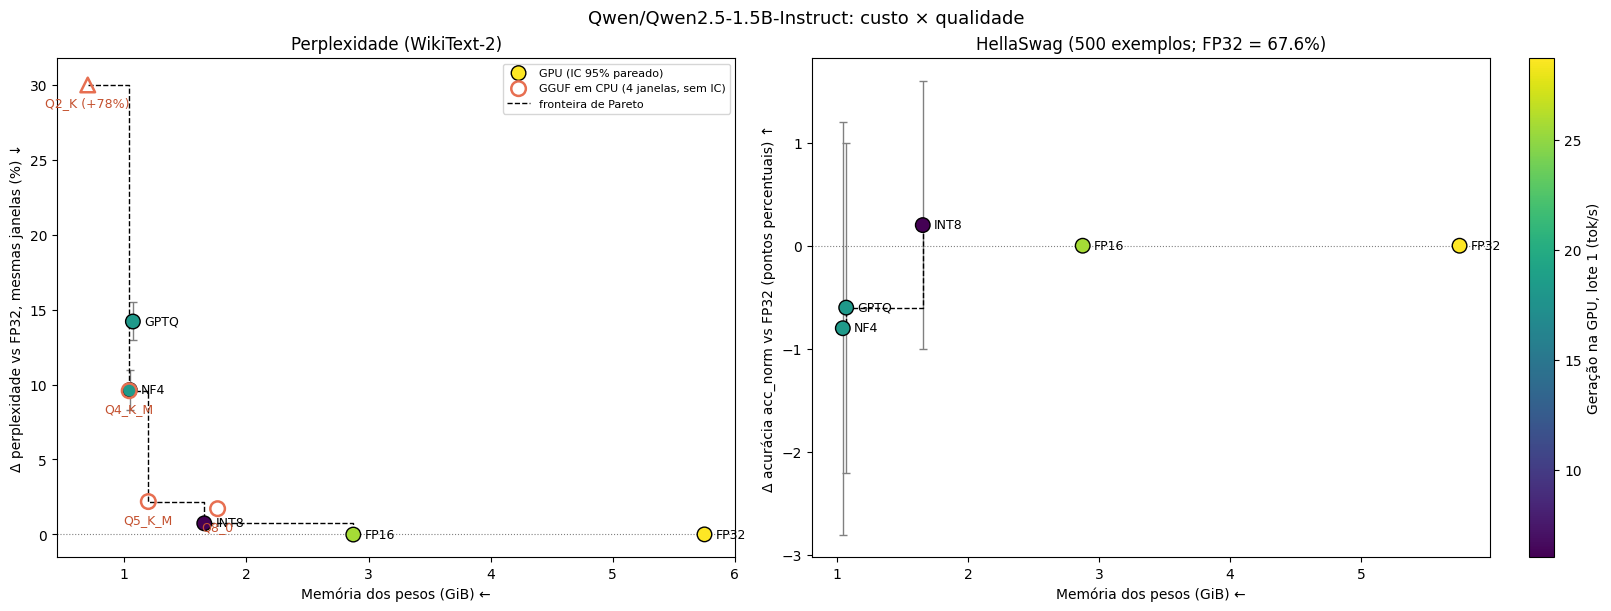

In [ ]:
# Custo × qualidade em um só gráfico. A linha em degraus liga os pontos da fronteira de Pareto:
# as técnicas que nenhuma outra supera ao mesmo tempo em memória e em qualidade.
# Os dois painéis mostram a diferença contra a referência, com o IC pareado do bootstrap.
Y_MAX_PPL = 30   # Δ de perplexidade acima disso (%) aparece no topo, com o valor escrito

def fronteira(x, y, maior_melhor=False):
    sinal = -1 if maior_melhor else 1
    pts, melhor = [], np.inf
    for xi, yi in sorted(zip(x, y)):
        if np.isfinite(yi) and sinal * yi < melhor:
            pts.append((xi, yi)); melhor = sinal * yi
    return np.array(pts)

def rotulo(t):
    return (t.replace(" (bnb 4-bit)", "").replace(" (LLM.int8)", "").replace(" 4-bit", "")
             .replace("GGUF ", ""))

def painel(ax, dados, col, inf, sup, titulo, ylabel, maior_melhor=False, y_max=None):
    g = dados[dados["plataforma"] == "GPU"]
    c = dados[(dados["plataforma"] == "CPU") & dados[col].notna()]
    y_vis = dados[col].clip(upper=y_max) if y_max else dados[col]
    ax.errorbar(g["memória_GB"], g[col], yerr=[g[col] - g[inf], g[sup] - g[col]],
                fmt="none", ecolor="gray", elinewidth=1, capsize=3, zorder=1)
    sc = ax.scatter(g["memória_GB"], g[col], c=g["geração_tok_s"], cmap="viridis", s=110,
                    edgecolor="black", zorder=3, label="GPU (IC 95% pareado)",
                    vmin=sintese["geração_tok_s"][sintese["plataforma"] == "GPU"].min(),
                    vmax=sintese["geração_tok_s"][sintese["plataforma"] == "GPU"].max())
    if len(c):
        fora = c[col] > y_max if y_max else pd.Series(False, index=c.index)
        ax.scatter(c.loc[~fora, "memória_GB"], c.loc[~fora, col], facecolor="none", edgecolor="#e76f51",
                   s=110, lw=1.8, zorder=3, label=f"GGUF em CPU ({N_WIN_GGUF} janelas, sem IC)")
        ax.scatter(c.loc[fora, "memória_GB"], y_vis[c.index][fora], marker="^", facecolor="none",
                   edgecolor="#e76f51", s=110, lw=1.8, zorder=3)
    fr = fronteira(dados["memória_GB"], dados[col], maior_melhor)
    if len(fr):
        ax.step(fr[:, 0], np.clip(fr[:, 1], None, y_max) if y_max else fr[:, 1], where="post",
                ls="--", color="black", lw=1, zorder=2, label="fronteira de Pareto")
    for t, r in dados[dados[col].notna()].iterrows():
        texto = rotulo(t) + (f" ({r[col]:+.0f}%)" if y_max and r[col] > y_max else "")
        cpu = r["plataforma"] == "CPU"                 # GPU à direita do ponto, CPU abaixo
        ax.annotate(texto, (r["memória_GB"], y_vis[t]), xytext=(0, -13) if cpu else (8, 0),
                    textcoords="offset points", ha="center" if cpu else "left", va="center",
                    fontsize=9, color="#c4512f" if cpu else "black")
    ax.axhline(0, color="gray", lw=0.8, ls=":")
    if y_max:
        ax.set_ylim(top=y_max * 1.06)
    ax.set_xlabel("Memória dos pesos (GiB) ←"); ax.set_ylabel(ylabel); ax.set_title(titulo)
    return sc

tem_hs = "Δacc_pp" in sintese and sintese["Δacc_pp"].notna().any()
fig, axes = plt.subplots(1, 2 if tem_hs else 1, figsize=(16 if tem_hs else 8.5, 6), squeeze=False,
                         layout="constrained")

sc = painel(axes[0, 0], sintese, "Δppl_%", "Δppl_ic_inf", "Δppl_ic_sup",
            "Perplexidade (WikiText-2)", f"Δ perplexidade vs {REF}, mesmas janelas (%) ↓", y_max=Y_MAX_PPL)
axes[0, 0].legend(loc="upper right", fontsize=8)
if tem_hs:
    n_hs = int(pd.read_csv(CSV_TAREFA)["n_exemplos"].max())
    painel(axes[0, 1], sintese, "Δacc_pp", "Δacc_ic_inf", "Δacc_ic_sup",
           f"HellaSwag ({n_hs} exemplos; {REF} = {sintese.loc[REF, 'acc_norm_%']:.1f}%)",
           f"Δ acurácia acc_norm vs {REF} (pontos percentuais) ↑", maior_melhor=True)
fig.colorbar(sc, ax=axes.ravel().tolist(), label="Geração na GPU, lote 1 (tok/s)", fraction=0.025, pad=0.02)
fig.suptitle(f"{MODEL_ID}: custo × qualidade", fontsize=13)
plt.show()

### Leitura do gráfico de custo × qualidade

**Como ler.** Cada ponto é uma técnica. No painel da perplexidade, mais à esquerda e mais abaixo é melhor; no do HellaSwag, mais à esquerda e mais acima. A cor indica a velocidade de geração na GPU (lote 1), e os pontos vazados são GGUF em CPU. A linha tracejada é a **fronteira de Pareto**: nenhuma técnica fora dela é, ao mesmo tempo, menor e melhor que uma técnica sobre ela.

**Perplexidade.** A fronteira passa por FP16, INT8, Q5_K_M, Q4_K_M/NF4 e Q2_K. Duas técnicas ficam fora dela:

- o **FP32**, que tem a mesma qualidade do FP16 com o dobro da memória;
- o **GPTQ**, porque o NF4 ocupa a mesma memória e perde menos qualidade.

Q4_K_M e NF4 aparecem sobrepostos por coincidência: os dois marcam +9,6%, mas o GGUF é medido em 4 janelas e o NF4 em 32 (nas mesmas 4 janelas, o NF4 marca +7,2%). Como os pontos GGUF não têm intervalo de confiança, a posição deles na fronteira é incerta.

**HellaSwag.** A fronteira desenhada (NF4 → GPTQ → INT8) não tem significado: todas as barras de erro cruzam o zero, e, nesta tarefa, as técnicas empatam.

**Resposta à pergunta, por orçamento de memória dos pesos** (este modelo, nesta T4):

| Memória disponível | Escolha | Custo medido |
|---|---|---|
| ≥ 2,9 GiB, em GPU | **FP16** (BF16 em Ampere ou mais nova) | Sem perda; a mais rápida |
| ≈ 1,7 GiB | **INT8** em GPU ou **Q8_0** em CPU | +0,7% a +1,7% de perplexidade; o INT8 gera ~4× mais devagar que o FP16 |
| ≈ 1,2 GiB, em CPU | **Q5_K_M** | +2,2% de perplexidade (4 janelas) |
| ≈ 1,05 GiB | **NF4** em GPU ou **Q4_K_M** em CPU | +7% a +10% de perplexidade, sem perda detectável no HellaSwag; NF4 a ~0,7× da velocidade do FP16 |
| < 1 GiB | **Q2_K**, só sem alternativa | +78% de perplexidade |

O pico de memória real é maior que o dos pesos, por causa das ativações e do KV cache (ver a análise de lote a seguir).

### Tamanho de lote: quando a quantização acelera?

Com lote 1, cada passo da geração lê todos os pesos para produzir um único token. Se o *overhead* fixo de cada passo dominar, ele esconde a diferença entre ler 2,9 ou 1,05 GiB. Gerar várias sequências ao mesmo tempo dilui esse *overhead*, e a leitura dos pesos passa a pesar mais, até o ponto em que o cálculo se torna o gargalo.

> **Hipótese.** Com lotes maiores, os métodos de 4 bits devem ganhar vantagem relativa sobre o FP16, pelo menos até o lote em que o cálculo passa a dominar.

Geração (tok/s agregados, mediana):


lote,1,8,32
técnica,,,
FP32,28.4,141.9,505.7
FP16,27.3,191.5,808.4
INT8 (LLM.int8),6.0,47.8,183.5
NF4 (bnb 4-bit),19.2,133.4,566.8
GPTQ 4-bit,18.2,152.7,528.7


Speedup sobre o FP16 em cada lote:


lote,1,8,32
técnica,,,
FP32,1.04,0.74,0.63
FP16,1.00,1.00,1.00
INT8 (LLM.int8),0.22,0.25,0.23
NF4 (bnb 4-bit),0.70,0.70,0.70
GPTQ 4-bit,0.67,0.80,0.65


Pico de VRAM durante a geração (GiB):


lote,1,8,32
técnica,,,
FP32,5.77,5.86,6.09
FP16,2.89,2.93,3.09
INT8 (LLM.int8),1.67,1.72,1.88
NF4 (bnb 4-bit),1.14,1.19,1.35
GPTQ 4-bit,1.09,1.13,1.29


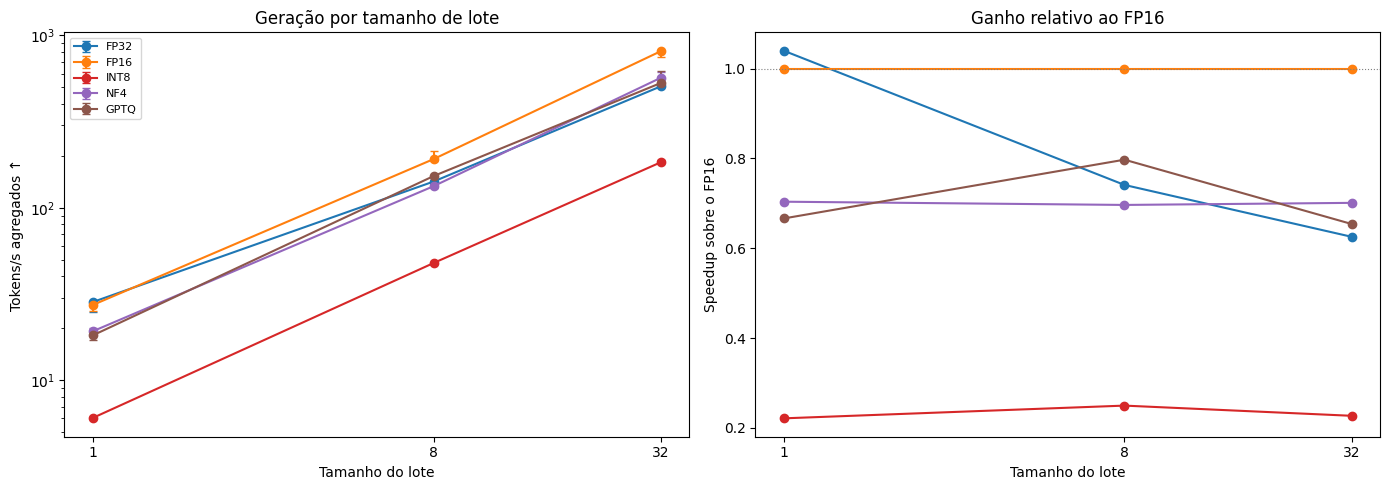

In [ ]:
# Velocidade de geração conforme o tamanho do lote (mediana; barras = mínimo e máximo das repetições).
if os.path.exists(CSV_LOTES):
    dl = pd.read_csv(CSV_LOTES)
    ordem_l = [t for t in ORDEM if t in set(dl["técnica"])]
    agg = dl.groupby(["técnica", "lote"])["tok_s"].agg(["median", "min", "max"]).reset_index()
    tok_lote = agg.pivot(index="técnica", columns="lote", values="median").loc[ordem_l]
    vram_lote = dl.groupby(["técnica", "lote"])["vram_pico_GB"].max().unstack().loc[ordem_l]
    base = "FP16" if "FP16" in tok_lote.index else REF
    speedup = tok_lote / tok_lote.loc[base]

    print("Geração (tok/s agregados, mediana):")
    display(tok_lote.round(1))
    print(f"Speedup sobre o {base} em cada lote:")
    display(speedup.round(2))
    print("Pico de VRAM durante a geração (GiB):")
    display(vram_lote.round(2))
    erros = dl[dl["erro"].fillna("") != ""]
    if len(erros):
        print("Lotes que falharam:"); display(erros[["técnica", "lote", "erro"]])

    cores = dict(zip(ORDEM, plt.cm.tab10(np.arange(len(ORDEM)))))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    for t in ordem_l:
        a = agg[agg["técnica"] == t]
        ax1.errorbar(a["lote"], a["median"], yerr=[a["median"] - a["min"], a["max"] - a["median"]],
                     marker="o", capsize=3, color=cores[t], label=rotulo(t))
        ax2.plot(speedup.columns, speedup.loc[t], marker="o", color=cores[t], label=rotulo(t))
    for ax in (ax1, ax2):
        ax.set_xscale("log", base=2); ax.set_xticks(list(tok_lote.columns))
        ax.set_xticklabels([str(b) for b in tok_lote.columns]); ax.set_xlabel("Tamanho do lote")
    ax1.set_yscale("log"); ax1.set_ylabel("Tokens/s agregados ↑"); ax1.set_title("Geração por tamanho de lote")
    ax1.legend(fontsize=8)
    ax2.axhline(1, color="gray", lw=0.8, ls=":")
    ax2.set_ylabel(f"Speedup sobre o {base}"); ax2.set_title(f"Ganho relativo ao {base}")
    plt.tight_layout(); plt.show()
else:
    print("Sem medições de lote: rode as Partes 1–3 com MEDIR_LOTES = True.")

### Resultado: a quantização não acelerou a geração em nenhum lote

**Hipótese refutada.** O FP16 foi o mais rápido em todos os lotes. O NF4 ficou em ~0,70× do FP16 nos três lotes, o GPTQ entre 0,65× e 0,80×, e o INT8 em ~0,23×.

**Por quê: o tempo por passo quase não muda com o lote.** Do lote 1 ao 32, o FP16 vai de 27 para 808 tok/s (29,6×) processando 32× mais tokens por passo: cada passo ficou só ~8% mais lento. NF4, GPTQ e INT8 escalam do mesmo jeito (29× a 31×). Mesmo com 32 sequências, portanto, o tempo é dominado por custos fixos por passo (lançar centenas de kernels pequenos, a lógica de geração em Python), e não pela leitura dos pesos nem pelo cálculo. Os kernels de 4 e 8 bits acrescentam etapas de desquantização a esse custo fixo, por isso perdem para o FP16 por uma razão quase constante.

**O teto teórico confirma.** A T4 lê ~320 GB/s. Ler os 3,1 GB do FP16 a cada token daria um limite de ≈ 100 tok/s com lote 1, e o medido foi 27 tok/s. Só cerca de um quarto do tempo de cada passo é leitura de pesos, então reduzir essa leitura em 2,75× rende pouco.

**A exceção é o FP32**, que cai de 1,04× para 0,63× do FP16. Sem *tensor cores*, o cálculo em FP32 começa a pesar já no lote 32: a vazão cresce só 18× de um extremo ao outro.

**Memória e KV cache.** O pico de VRAM da geração quase não cresce com o lote (+0,2 GiB do lote 1 ao 32). O Qwen2.5-1.5B usa *grouped-query attention* com só 2 cabeças de chave/valor, e o KV cache custa ~28 KiB por token em FP16 (28 camadas × 2 tensores × 2 cabeças × 128 dimensões × 2 bytes). Com 32 sequências de ~135 tokens, são ~0,12 GiB. Em contextos longos, a conta muda: 32 mil tokens de uma só sequência ocupam ~0,9 GiB, quase o tamanho dos pesos em NF4. Nesse regime, quantizar os pesos resolve só parte do orçamento de memória.

**Onde a quantização acelera.** A quantização deve acelerar em motores que eliminam o custo fixo por passo (*CUDA graphs*, *continuous batching* e kernels fundidos, como vLLM, TensorRT-LLM ou llama.cpp em GPU), em modelos maiores, nos quais ler os pesos domina o tempo, e na CPU (Parte 4). Os motores e os modelos maiores não foram medidos aqui.

**Atenção à versão.** Numa execução anterior deste notebook, com PyTorch 2.11, a geração em FP16 com lote 1 ficou em ~11 tok/s, abaixo do NF4 (16 tok/s) e do GPTQ (18 tok/s). Nesta execução, com PyTorch 2.15, o FP16 subiu para 26 tok/s, e os métodos de 4 bits ficaram praticamente onde estavam. A conclusão de que "4 bits gera mais rápido" se inverteu só com a atualização do framework. A velocidade deve ser medida na pilha de software que vai ser usada, com as versões fixadas.

In [ ]:
# Saída qualitativa: as primeiras palavras geradas por cada variante, com o mesmo prompt e decodificação gulosa.
textos = pd.concat([pd.read_csv(c)[["técnica", "texto_gerado"]] for c in (CSV_GPU, CSV_GGUF) if os.path.exists(c)])
for _, r in textos.iterrows():
    print(f"[{r['técnica']}]\n  {PROMPT} {str(r['texto_gerado']).strip()[:160]} ...\n")

[FP32]
  The history of artificial intelligence began in the 1950s, when researchers first started to explore how computers could be programmed to perform tasks that required human-like reasoning. Since then, AI ha ...

[FP16]
  The history of artificial intelligence began in the 1950s, when researchers first started to explore how computers could be programmed to perform tasks that required human-like reasoning. Since then, AI ha ...

[INT8 (LLM.int8)]
  The history of artificial intelligence began in the 1950s, when researchers first started to explore how computers could be programmed to perform tasks that were traditionally done by humans. Since then, A ...

[NF4 (bnb 4-bit)]
  The history of artificial intelligence began with the invention of the first computer in 1946. The term "artificial intelligence" was coined by John McCarthy, who founded the field and developed the rule-b ...

[GPTQ 4-bit]
  The history of artificial intelligence began in the 1950s, when researchers first s

### Saída qualitativa

Com o mesmo prompt e decodificação gulosa, FP32 e FP16 geram o mesmo texto. INT8, GPTQ, Q8_0, Q5_K_M e Q4_K_M divergem nas palavras, mas mantêm o conteúdo. O NF4 tomou outro caminho logo no início e cometeu um erro factual: atribuiu a John McCarthy o sistema MYCIN, que foi desenvolvido em Stanford por Edward Shortliffe nos anos 1970. O Q2_K também muda de rumo e passa a falar do ENIAC.

É um único prompt, então serve como ilustração, não como medida. Mas mostra o tipo de dano que a perplexidade capta e o HellaSwag não: detalhes factuais, mais do que a escolha entre opções plausíveis.

## Quando usar cada técnica

A coluna "custo medido" vale para o Qwen2.5-1.5B na T4 com `transformers`, comparado ao FP32 (perplexidade em 32 janelas, salvo indicação). A velocidade é a da geração com lote 1.

| Cenário | Técnica | Custo medido | Por quê |
|---|---|---|---|
| GPU Ampere ou mais nova, modelo cabe em 16 bits | **BF16** | +0,09% de perplexidade; concordância de 97,5% (medido em outra GPU) | 2× menor que FP32, sem calibração, sem risco de estouro |
| GPU antiga (T4, V100), modelo cabe em 16 bits | **FP16** | Sem perda (−0,01% de perplexidade; HellaSwag igual). A mais rápida em todos os lotes | 2× menor que FP32 e *forward* 3,7× mais rápido; checar a perplexidade, pois pode estourar |
| Modelo não cabe em 16 bits e a qualidade é prioridade | **INT8 (LLM.int8)** | +0,7% de perplexidade; sem perda no HellaSwag. Geração ~4× mais lenta que a do FP16 | 1,7× menos memória que o FP16, sem calibração; serve quando a velocidade não importa |
| Pouca VRAM, experimentação ou *fine-tuning* (QLoRA) | **NF4** | +9,6% de perplexidade; HellaSwag −0,8 ponto (dentro do ruído). Geração a ~0,7× do FP16 | 2,75× menos memória que o FP16, quantiza em segundos, sem calibração; aqui, mais fiel que o GPTQ |
| Servir em 4 bits em GPU, com motor de inferência | **GPTQ** | +14,2% de perplexidade; HellaSwag −0,6 ponto (dentro do ruído). Geração a ~0,7× do FP16 com `transformers` | Checkpoint pronto e kernels dedicados; o ganho de velocidade depende do motor (vLLM, TGI), não medido aqui. O AWQ é uma alternativa, também não medida |
| CPU, notebook, borda ou servidor sem GPU | **GGUF**: Q4_K_M, ou Q5_K_M se couber | Q4_K_M: +9,6%, 7,3 tok/s. Q5_K_M: +2,2%, 5,3 tok/s. Q8_0: +1,7%, 4,8 tok/s (4 janelas, CPU do Colab) | Um arquivo, sem PyTorch; na CPU, menos bits significa mais velocidade |

**Conclusões**

1. **Reduzir de 32 para 16 bits é gratuito em qualidade.** FP16 e FP32 têm a mesma perplexidade, a mesma concordância e a mesma acurácia no HellaSwag; a escolha entre FP16 e BF16 depende do hardware.
2. **Abaixo de 16 bits, o desafio são os *outliers*.** Todas as técnicas modernas resolvem isso com **escalas por bloco** ou precisão mista, e o tamanho do bloco importa.
3. **Menos bits não significou mais velocidade na GPU.** Com `transformers` na T4, nenhuma técnica abaixo de 16 bits gerou mais rápido que o FP16, em nenhum lote: o tempo é dominado por custos fixos por passo, e desquantizar só os aumenta. Na CPU, com o llama.cpp, menos bits foi mais rápido. A velocidade depende do motor, do hardware e até da versão das bibliotecas.
4. **Em 4 bits, a compressão é a mesma, mas a fidelidade não.** NF4, GPTQ e Q4_K_M ocupam ~5,8–6 bits por peso, mas o NF4 perdeu significativamente menos perplexidade que o GPTQ (+9,6% contra +14,2%), ao contrário do que se esperaria de um método com calibração. O nome da técnica não garante a qualidade: é preciso medir com o checkpoint e a configuração que serão usados.
5. **Perplexidade e tarefa contam histórias diferentes.** Os 10–14% de perplexidade a mais nos métodos de 4 bits não viraram perda detectável no HellaSwag. A perplexidade é a métrica mais sensível para comparar técnicas, mas a decisão final deve vir de uma avaliação na tarefa real.
6. **Em modelos pequenos, a memória não se resume aos pesos quantizáveis.** A matriz de *embedding*, mantida em 16 bits, ocupa ~40% do modelo em NF4, e, em contextos longos, o KV cache passa a competir com os pesos.

**Referências:** Dettmers et al. (2022), *LLM.int8()*, arXiv:2208.07339 · Frantar et al. (2022), *GPTQ*, arXiv:2210.17323 · Dettmers et al. (2023), *QLoRA*, arXiv:2305.14314 · Zellers et al. (2019), *HellaSwag*, arXiv:1905.07830.

---
# Para ir além — técnicas avançadas (Capítulo 9)

> Esta seção **não é executada** e não faz parte do benchmark. Os trechos de código são ilustrativos: usam outros modelos (OPT, BitNet) e exigem bibliotecas e ambientes próprios. Os números das figuras vêm dos artigos originais, não deste notebook.

Cada técnica ataca um limite que apareceu nas medições acima:

- **FlexGen** ataca o limite de memória: quando nem os pesos quantizados cabem na GPU, distribui pesos, KV cache e ativações entre GPU, CPU e disco, e comprime pesos e cache em 4 bits. Troca latência por *throughput* em lote.
- **SmoothQuant** ataca os *outliers* de ativação (Parte 2): transfere a dificuldade das ativações para os pesos e permite multiplicar tudo em INT8, onde o LLM.int8() recorre ao FP16.
- **BitNet** leva a compressão ao extremo, com pesos de 1 bit, mas exige treinar o modelo já nesse formato.

## FlexGen
```
python -m flexgen.flex_opt --model facebook/opt-6.7b --percent 50 50 50 50 50 50
```
------------------------------


```
offload_dir = "./flexgen_offload"
env = ExecutionEnv.create(offload_dir)   # onde o FlexGen pode despejar o que
                                         # não cabe nem na VRAM nem na RAM

policy = Policy(len(prompts), 1,
                100, 0,   # pesos: GPU% / CPU%
                0, 100,               # cache de atenção: 100% na CPU
                                      #(um cache comprimido não pode ser dividido)
                100, 0,               # ativações: 100% na GPU
                                      #(elas também não podem ser divididas)
                overlap=True, sep_layer=True, pin_weight=True,
                cpu_cache_compute=True, attn_sparsity=1.0,
                compress_weight=True,
                comp_weight_config=CompressionConfig(
                    num_bits=4, group_size=64,
                    group_dim=0, symmetric=False),
                compress_cache=True,
                comp_cache_config=CompressionConfig(
                    num_bits=4, group_size=64,
                    group_dim=2, symmetric=False)
                )
path = "~/opt_weights"                # cache local dos pesos convertidos
model = OptLM(model_id, env, path, policy)
```

## SmoothQuant

```
from smoothquant.smooth import smooth_lm

model_fp16 = OPTForCausalLM.from_pretrained("facebook/opt-1.3b", torch_dtype=torch.float16, device_map={"": 0})

act_scales_path = get_act_scales("opt-1.3b")
act_scales = torch.load(act_scales_path)

smooth_lm(model_fp16, act_scales, 0.5)  # alpha = 0.5
```

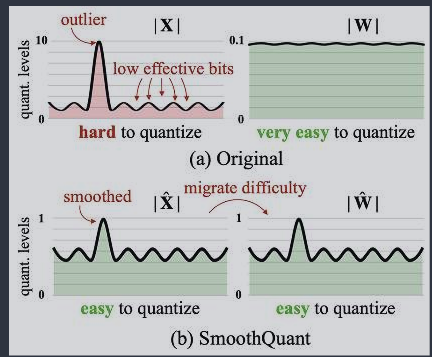

*Figura: o SmoothQuant usa um fator de escala por canal para migrar a dificuldade de quantização das ativações para os pesos (Xiao et al., 2023).*

## BitNet

```
from bitnet import BitNetTransformer

bitnet = BitNetTransformer(
    num_tokens=20000,   # tamanho do vocabulário
    dim=1024,           # dimensão do embedding
    depth=6,            # número de camadas
    heads=8,            # cabeças de atenção
    ff_mult=4,          # multiplicador da camada oculta do feed-forward
)
```
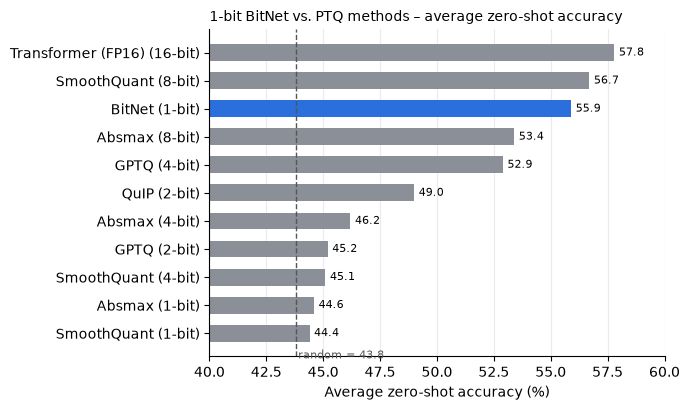

*Figura: acurácia zero-shot média reportada pelos autores do BitNet (Wang et al., 2023); não medida neste notebook.*

| | **FlexGen** | **SmoothQuant** | **BitNet** |
|---|---|---|---|
| O que faz | Descarrega pesos / KV cache / ativações entre GPU, CPU e disco; compressão de 4 bits | Suaviza outliers de ativação → pesos + ativações INT8 precisos | Pesos de 1 bit (BitLinear), ativações de 8 bits, treinado do zero |
| Precisa de treinamento? | Não | Não (pós-treinamento, usa escalas de calibração) | **Sim** (do zero), ou use um modelo BitNet já publicado |
| Melhor para | Trabalhos em lote orientados a **throughput** em GPUs pequenas | Modelos com **> 6–7B** de parâmetros em que o INT8 ingênuo falha | Orçamentos apertados de **memória / energia**, implantação em CPU |
| Principal limitação | Maior latência; apenas NVIDIA/CUDA | Precisa de kernels/motor INT8 para ganhos reais de velocidade | Custo de treinamento; poucos modelos prontos; suporte a GPU no `bitnet.cpp` pendente |
| Parâmetro-chave | `Policy`: `--percent`, configuração de compressão | `alpha` (0,5 para < 100B) | Tamanho do modelo / receita de treinamento |

Para a maioria dos casos de uso em produção com modelos de linguagem pequenos locais, os métodos tradicionais de quantização do capítulo 6 são uma boa escolha. Para tarefas de nicho com conteúdo mais complexo e não estruturado (ou modelos base maiores), estas estratégias avançadas oferecem folga adicional.

### Referências
* FlexGen – https://arxiv.org/abs/2303.06865 · https://github.com/FMInference/FlexLLMGen
* SmoothQuant – https://arxiv.org/abs/2211.10438 · https://github.com/mit-han-lab/smoothquant
* BitNet – https://arxiv.org/abs/2310.11453 · https://github.com/microsoft/BitNet · https://github.com/kyegomez/BitNet
* OPT – https://arxiv.org/abs/2205.01068 · LAMBADA – https://huggingface.co/datasets/cimec/lambada